# Paisabazaar Credit Score & Credit Risk Analysis

**Author :** Nitin Tiwari

**Tools :** Python, Pandas, NumPy, Matplotlib, Seaborn

**Dataset:** 100,000 monthly records of 12,500 customers, 28 features

# Project Summary

This project analyses 100,000 monthly records of 12,500 Paisabazaar customers to understand which financial behaviours are linked to credit score (Poor, Standard, Good). The dataset covers demographics, income, loans, credit cards, outstanding debt, credit utilisation, payment delays, and payment behaviour.

I cleaned the data (placeholder values, data types, outlier checks), engineered new features such as debt-to-income ratio, and used univariate, bivariate and multivariate analysis to compare customer groups.

The goal is to identify the factors most associated with credit risk and to suggest how Paisabazaar can improve risk assessment and product recommendations.

## Key Findings
- **Customers with 5 or more loans are the highest-risk segment.** They make up 30.5% of all records but 55.0% of all Poor-score records, and more than half of them have a Poor score.
- **Payment behaviour separates the score groups clearly.** Poor-score customers average 15.81 delayed payments against 8.56 for Good, and customers who pay only the minimum amount are about 3 times more likely to have a Poor score (39.6% vs 13.4%).
- **Income alone does not explain credit score.** Median income is 32,065 for Poor and 44,928 for Good customers, but the ranges overlap heavily. Debt-to-income separates the groups far better (median 0.063 vs 0.012).
- **Credit utilization shows no real link with score.** It is about 32% in all three groups, so it should not be used alone as a risk signal.

# **GitHub Link -**

**GitHub Repository:** https://github.com/nitintiwari-Lab/paisabazaar-credit-risk-analysis

# Problem Statement

Paisabazaar holds financial and credit data for 12,500 customers over 8 months (100,000 records). With this much data, it is hard to tell which customer behaviours actually signal higher credit risk. Income alone does not explain a credit score, so other factors such as payment delays, credit utilisation, debt and number of loans need to be compared.

# Business Objective

Identify the financial and payment behaviours most associated with Poor credit scores, so that Paisabazaar can:
- improve credit-risk assessment,
- spot high-risk customer segments early,
- recommend more suitable financial products.

# Questions This Analysis Answers

1. Which behaviours separate Poor, Standard and Good credit scores?
2. Does income alone explain credit score?
3. Which customer segment carries the highest credit risk?

## 1. Data Overview

### Import Libraries

In [114]:
# Import libraries
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)


### Dataset Loading

In [115]:
# Load dataset (the CSV is expected in the data/ folder of the repository)
DATA_PATH = '../data/paisabazaar_dataset.csv'
paisabazaar_df = pd.read_csv(DATA_PATH)
print(f"Loaded {paisabazaar_df.shape[0]:,} rows and {paisabazaar_df.shape[1]} columns")

# To run this notebook in Google Colab, comment out the lines above and uncomment these:

# from google.colab import drive
# drive.mount('/content/drive')

# # Load Dataset
# paisabazaar_df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/paisabazar dataset.csv')
# print(f"Loaded {paisabazaar_df.shape[0]:,} rows and {paisabazaar_df.shape[1]} columns")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded 100,000 rows and 28 columns


### Dataset Rows & Columns count

In [116]:
# Dataset Rows & Columns count
paisabazaar_df.shape

(100000, 28)

### Dataset Information

In [117]:
# Dataset Info
paisabazaar_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        100000 non-null  int64  
 1   Customer_ID               100000 non-null  int64  
 2   Month                     100000 non-null  int64  
 3   Name                      100000 non-null  object 
 4   Age                       100000 non-null  float64
 5   SSN                       100000 non-null  float64
 6   Occupation                100000 non-null  object 
 7   Annual_Income             100000 non-null  float64
 8   Monthly_Inhand_Salary     100000 non-null  float64
 9   Num_Bank_Accounts         100000 non-null  float64
 10  Num_Credit_Card           100000 non-null  float64
 11  Interest_Rate             100000 non-null  float64
 12  Num_of_Loan               100000 non-null  float64
 13  Type_of_Loan              100000 non-null  ob

All columns report 100,000 non-null values, but that does not mean the data is clean. `Age` is stored as a float and needs converting, and some text columns contain placeholder values (such as `NM`). Both are handled in the data cleaning section.

`Name` and `SSN` are personal identifiers that are not needed for the analysis, so they were dropped.

In [118]:
# Name and SSN are personal identifiers and are not needed for the analysis
paisabazaar_df = paisabazaar_df.drop(columns=['Name', 'SSN'])

### Dataset First Look

In [119]:
paisabazaar_df.head()

,ID,Customer_ID,Month,Age,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,5634,3392,1,23.0,Scientist,19114.12,1824.843333,3.0,4.0,3.0,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3.0,7.0,11.27,4.0,Good,809.98,26.822620,265.0,No,49.574949,21.46538,High_spent_Small_value_payments,312.494089,Good
1,5635,3392,2,23.0,Scientist,19114.12,1824.843333,3.0,4.0,3.0,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3.0,4.0,11.27,4.0,Good,809.98,31.944960,266.0,No,49.574949,21.46538,Low_spent_Large_value_payments,284.629162,Good
2,5636,3392,3,23.0,Scientist,19114.12,1824.843333,3.0,4.0,3.0,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3.0,7.0,11.27,4.0,Good,809.98,28.609352,267.0,No,49.574949,21.46538,Low_spent_Medium_value_payments,331.209863,Good
3,5637,3392,4,23.0,Scientist,19114.12,1824.843333,3.0,4.0,3.0,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",5.0,4.0,6.27,4.0,Good,809.98,31.377862,268.0,No,49.574949,21.46538,Low_spent_Small_value_payments,223.451310,Good
4,5638,3392,5,23.0,Scientist,19114.12,1824.843333,3.0,4.0,3.0,4.0,"Auto Loan, Credit-Builder Loan, Personal Loan,...",6.0,4.0,11.27,4.0,Good,809.98,24.797347,269.0,No,49.574949,21.46538,High_spent_Medium_value_payments,341.489231,Good


#### Duplicate Values

In [120]:
# Count fully duplicated rows
print("Duplicate rows:", paisabazaar_df.duplicated().sum())

Duplicate rows: 0


#### Missing Values/Null Values

In [121]:
# Count missing values per column (showing only columns that have any)
missing = paisabazaar_df.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "No null values in any column")

No null values in any column


In [122]:
# Look for placeholder strings that hide missing values in text columns
placeholders = ['NM', '_', '', 'nan', 'NA', 'N/A', '!@9#%8']

for col in paisabazaar_df.select_dtypes(include='object').columns:
    count = paisabazaar_df[col].isin(placeholders).sum()
    if count > 0:
        print(f"{col}: {count:,} placeholder values")

Payment_of_Min_Amount: 12,007 placeholder values


No duplicate rows and no null values were found. However, the placeholder check found hidden missing values in `Payment_of_Min_Amount` (12,007 rows labelled `NM`). These are treated in the data cleaning section.

### Repeated Customers

In [123]:
# Check whether the same customer appears in multiple rows
print("Total rows:", len(paisabazaar_df))
print("Unique customers:", paisabazaar_df['Customer_ID'].nunique())
print()
print("Rows per customer:")
print(paisabazaar_df.groupby('Customer_ID').size().describe())

Total rows: 100000
Unique customers: 12500

Rows per customer:
count    12500.0
mean         8.0
std          0.0
min          8.0
25%          8.0
50%          8.0
75%          8.0
max          8.0
dtype: float64


The dataset has 100,000 rows but only 12,500 unique customers. Every customer appears exactly 8 times (one record per month). The charts below therefore show patterns across customer-month records, not across unique customers.

### Key Observations

- The dataset has 100,000 rows and 28 columns, covering 12,500 customers with 8 monthly records each.
- There are no duplicate rows and no null values.
- `Payment_of_Min_Amount` has 12,007 hidden missing values labelled `NM`.
- `Age` is stored as a float and ranges from 14 to 56.
- The target variable `Credit_Score` has three classes: Poor, Standard and Good.

## 2. Understanding the Variables





In [124]:
# Dataset Columns
paisabazaar_df.columns

Index(['ID', 'Customer_ID', 'Month', 'Age', 'Occupation', 'Annual_Income',
       'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card',
       'Interest_Rate', 'Num_of_Loan', 'Type_of_Loan', 'Delay_from_due_date',
       'Num_of_Delayed_Payment', 'Changed_Credit_Limit',
       'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt',
       'Credit_Utilization_Ratio', 'Credit_History_Age',
       'Payment_of_Min_Amount', 'Total_EMI_per_month',
       'Amount_invested_monthly', 'Payment_Behaviour', 'Monthly_Balance',
       'Credit_Score'],
      dtype='object')

In [125]:
# Dataset Describe
paisabazaar_df.describe()

,ID,Customer_ID,Month,Age,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Total_EMI_per_month,Amount_invested_monthly,Monthly_Balance
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,80631.500000,25982.666640,4.500000,33.316340,50505.123449,4197.270835,5.368820,5.533570,14.53208,3.532880,21.08141,13.313120,10.470323,5.798250,1426.220376,32.285173,221.220460,107.699208,55.101315,392.697586
std,43301.486619,14340.543051,2.291299,10.764812,38299.422093,3186.432497,2.593314,2.067098,8.74133,2.446356,14.80456,6.237166,6.609481,3.867826,1155.129026,5.116875,99.680716,132.267056,39.006932,201.652719
min,5634.000000,1006.000000,1.000000,14.000000,7005.930000,303.645417,0.000000,0.000000,1.00000,0.000000,0.00000,0.000000,0.500000,0.000000,0.230000,20.000000,1.000000,0.000000,0.000000,0.007760
25%,43132.750000,13664.500000,2.750000,24.000000,19342.972500,1626.594167,3.000000,4.000000,7.00000,2.000000,10.00000,9.000000,5.380000,3.000000,566.072500,28.052567,144.000000,29.268886,27.959111,267.615983
50%,80631.500000,25777.000000,4.500000,33.000000,36999.705000,3095.905000,5.000000,5.000000,13.00000,3.000000,18.00000,14.000000,9.400000,5.000000,1166.155000,32.305784,219.000000,66.462304,45.156550,333.865366
75%,118130.250000,38385.000000,6.250000,42.000000,71683.470000,5957.715000,7.000000,7.000000,20.00000,5.000000,28.00000,18.000000,14.850000,8.000000,1945.962500,36.496663,302.000000,147.392573,71.295797,463.215683
max,155629.000000,50999.000000,8.000000,56.000000,179987.280000,15204.633333,11.000000,11.000000,34.00000,9.000000,62.00000,25.000000,29.980000,17.000000,4998.070000,50.000000,404.000000,1779.103254,434.191089,1183.930696


### Check Unique Values for each variable.

In [126]:
# Check Unique Values for each variable.
paisabazaar_df.nunique()

,0
ID,100000
Customer_ID,12500
Month,8
Age,43
Occupation,15
Annual_Income,12488
Monthly_Inhand_Salary,13241
Num_Bank_Accounts,12
Num_Credit_Card,12
Interest_Rate,34


### Data Dictionary

| Column | Type | Meaning |
|---|---|---|
| ID | ID | Unique record identifier |
| Customer_ID | ID | Customer identifier (12,500 customers) |
| Month | Numeric | Month number of the record (1 to 8) |
| Age | Numeric | Customer age in years |
| Occupation | Categorical | Customer's profession (15 types) |
| Annual_Income | Numeric | Yearly income |
| Monthly_Inhand_Salary | Numeric | Monthly take-home salary |
| Num_Bank_Accounts | Numeric | Number of bank accounts |
| Num_Credit_Card | Numeric | Number of credit cards |
| Interest_Rate | Numeric | Interest rate on credit (%) |
| Num_of_Loan | Numeric | Number of loans taken |
| Type_of_Loan | Text | Types of loans taken |
| Delay_from_due_date | Numeric | Days payments are delayed from the due date |
| Num_of_Delayed_Payment | Numeric | Number of delayed payments |
| Changed_Credit_Limit | Numeric | Change in credit limit (%) |
| Num_Credit_Inquiries | Numeric | Number of credit inquiries |
| Credit_Mix | Categorical | Quality of the credit mix (Bad, Standard, Good) |
| Outstanding_Debt | Numeric | Remaining debt amount |
| Credit_Utilization_Ratio | Numeric | Share of available credit in use (%) |
| Credit_History_Age | Numeric | Length of credit history in months |
| Payment_of_Min_Amount | Categorical | Whether only the minimum amount is paid (Yes, No, Unknown) |
| Total_EMI_per_month | Numeric | Total monthly EMI payments |
| Amount_invested_monthly | Numeric | Amount invested each month |
| Payment_Behaviour | Categorical | Spending and payment pattern |
| Monthly_Balance | Numeric | Balance left at the end of the month |
| **Credit_Score** | **Target** | **Poor, Standard or Good** |
| Debt_to_Income | Engineered | Outstanding_Debt divided by Annual_Income |

`Name` and `SSN` were dropped to protect personal information.

## 3. Data Wrangling

### 3.1 Age

In [127]:
# Convert Age from float to integer
paisabazaar_df['Age'] = paisabazaar_df['Age'].astype(int)


`Age` was converted from float to integer. Ages range from 14 to 56; all rows were kept, since younger customers (for example, students with education loans) can legitimately appear in the data.

### 3.2 Payment_of_Min_Amount

In [128]:
# Values before cleaning
paisabazaar_df['Payment_of_Min_Amount'].value_counts()

,count
Payment_of_Min_Amount,
Yes,52326
No,35667
NM,12007


In [129]:
# 'NM' (Not Mentioned) is not a valid Yes/No value, so label it as 'Unknown'
paisabazaar_df['Payment_of_Min_Amount'] = paisabazaar_df['Payment_of_Min_Amount'].replace('NM', 'Unknown')

paisabazaar_df['Payment_of_Min_Amount'].value_counts()

,count
Payment_of_Min_Amount,
Yes,52326
No,35667
Unknown,12007


12,007 rows had the value `NM` (Not Mentioned) in `Payment_of_Min_Amount`. Since `NM` is not a valid Yes/No answer, it was labelled `Unknown` instead of being converted to `No`, which would have added a wrong assumption to the data.

### 3.3 Annual_Income

In [130]:
# Summary of Annual_Income
print(paisabazaar_df['Annual_Income'].describe())
print()

# Check how extreme the high values are
print("99th percentile:", paisabazaar_df['Annual_Income'].quantile(0.99))
print("99.9th percentile:", paisabazaar_df['Annual_Income'].quantile(0.999))
print("Maximum:", paisabazaar_df['Annual_Income'].max())

# Count rows above the IQR upper limit
Q1 = paisabazaar_df['Annual_Income'].quantile(0.25)
Q3 = paisabazaar_df['Annual_Income'].quantile(0.75)
upper_limit = Q3 + 1.5 * (Q3 - Q1)
outlier_count = (paisabazaar_df['Annual_Income'] > upper_limit).sum()
print()
print(f"IQR upper limit: {upper_limit:,.0f}")
print(f"Rows above the limit: {outlier_count:,} ({outlier_count / len(paisabazaar_df):.1%})")

count    100000.000000
mean      50505.123449
std       38299.422093
min        7005.930000
25%       19342.972500
50%       36999.705000
75%       71683.470000
max      179987.280000
Name: Annual_Income, dtype: float64

99th percentile: 166891.76119999992
99.9th percentile: 178793.92
Maximum: 179987.28

IQR upper limit: 150,194
Rows above the limit: 2,000 (2.0%)


`Annual_Income` ranges from 7,006 to 179,987 with no extreme jump at the top (99.9th percentile is 178,794). The IQR rule flags 2,000 rows (2.0%) as outliers, but these are genuine high earners forming the natural right tail of the distribution, not data errors. All rows were kept.

### 3.4 Debt-to-Income Ratio

In [131]:
# Debt-to-income ratio: outstanding debt relative to annual income
paisabazaar_df['Debt_to_Income'] = paisabazaar_df['Outstanding_Debt'] / paisabazaar_df['Annual_Income']

paisabazaar_df['Debt_to_Income'].describe()

,Debt_to_Income
count,100000.000000
mean,0.060657
std,0.087425
min,0.000003
25%,0.009572
50%,0.028250
75%,0.069716
max,0.683252


`Debt_to_Income` (outstanding debt divided by annual income) was created to measure how heavy a customer's debt is relative to their earning capacity. It is used in the risk analysis later.

### 3.5 Validity Checks

In [132]:
# Check min, max and negative counts for key numeric columns
check_cols = [
    'Monthly_Inhand_Salary', 'Num_Bank_Accounts', 'Num_Credit_Card',
    'Interest_Rate', 'Num_of_Loan', 'Delay_from_due_date',
    'Num_of_Delayed_Payment', 'Credit_Utilization_Ratio', 'Outstanding_Debt'
]

summary = paisabazaar_df[check_cols].agg(['min', 'median', 'max']).T
summary['negative_rows'] = (paisabazaar_df[check_cols] < 0).sum()
summary

,min,median,max,negative_rows
Monthly_Inhand_Salary,303.645417,3095.905000,15204.633333,0
Num_Bank_Accounts,0.000000,5.000000,11.000000,0
Num_Credit_Card,0.000000,5.000000,11.000000,0
Interest_Rate,1.000000,13.000000,34.000000,0
Num_of_Loan,0.000000,3.000000,9.000000,0
Delay_from_due_date,0.000000,18.000000,62.000000,0
Num_of_Delayed_Payment,0.000000,14.000000,25.000000,0
Credit_Utilization_Ratio,20.000000,32.305784,50.000000,0
Outstanding_Debt,0.230000,1166.155000,4998.070000,0


All key numeric columns were checked for impossible values. There are no negative values, and the ranges are realistic (for example, 0 to 11 bank accounts and credit cards, interest rates from 1% to 34%, payment delays from 0 to 62 days, credit utilisation from 20% to 50%). No further cleaning was required for these columns.

### 3.6 Data Cleaning Summary

The dataset needed only light cleaning, and all 100,000 rows were kept for analysis. The `Payment_of_Min_Amount` column had 12,007 rows with the value `NM` (Not Mentioned). Since this is not a valid Yes/No answer, it was labelled `Unknown` instead of being converted to `No`. The `Age` column was stored as a float and was converted to integer, and all age values (14 to 56) were retained because younger customers can legitimately appear in the data, for example students with education loans.

The IQR rule flagged 2,000 rows (2.0%) as high `Annual_Income` outliers, but the maximum income (179,987) was close to the 99.9th percentile (178,794), so these were treated as genuine high earners and kept. All key numeric columns were also checked for impossible values, and no negative or unrealistic values were found. Finally, a new feature, `Debt_to_Income` (outstanding debt divided by annual income), was created to measure each customer's debt burden for the risk analysis.

## 4. Exploratory Data Analysis

### 4.1 Univariate Analysis

#### Chart 1: Credit Score Distribution

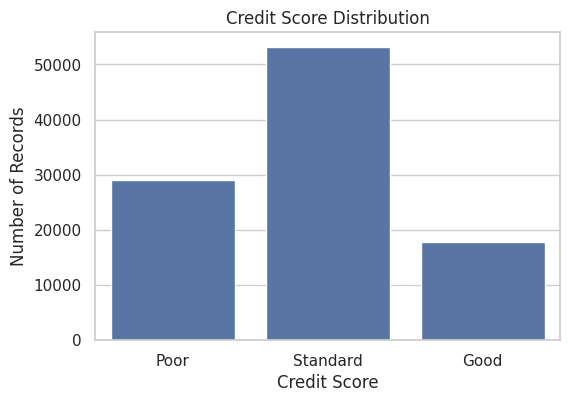

In [133]:
plt.figure(figsize=(6, 4))
sns.countplot(data=paisabazaar_df, x='Credit_Score', order=['Poor', 'Standard', 'Good'])
plt.title('Credit Score Distribution')
plt.xlabel('Credit Score')
plt.ylabel('Number of Records')
plt.show()

**Insight:** Standard is the largest group with 53,174 records (53.2%), followed by Poor with 28,998 (29.0%) and Good with 17,828 (17.8%).

**So what:** Fewer than 1 in 5 records has a Good score, and Poor outnumbers Good by about 1.6 to 1.

#### Chart 2: Age Distribution

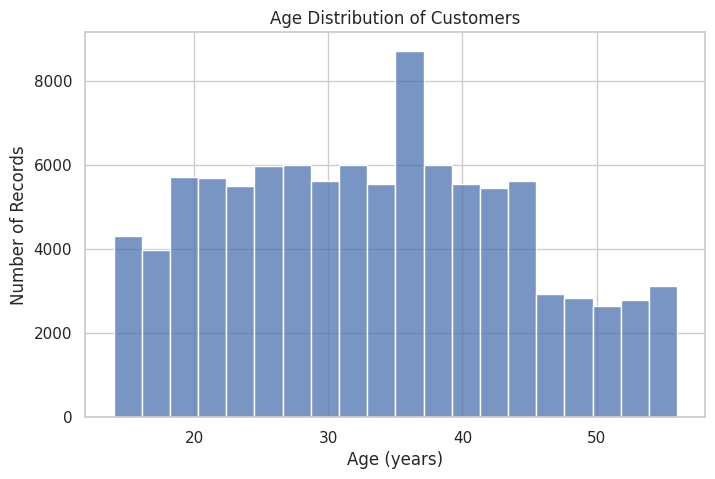

In [134]:
plt.figure(figsize=(8, 5))
sns.histplot(data=paisabazaar_df, x='Age', bins=20)
plt.title('Age Distribution of Customers')
plt.xlabel('Age (years)')
plt.ylabel('Number of Records')
plt.show()

**Insight:** Ages range from 14 to 56, with a median of 33. The middle 50% of records fall between ages 24 and 42.

**So what:** The customer base is mainly young and middle-aged adults, so products should be designed for this working-age group.

#### Chart 3: Annual Income Distribution

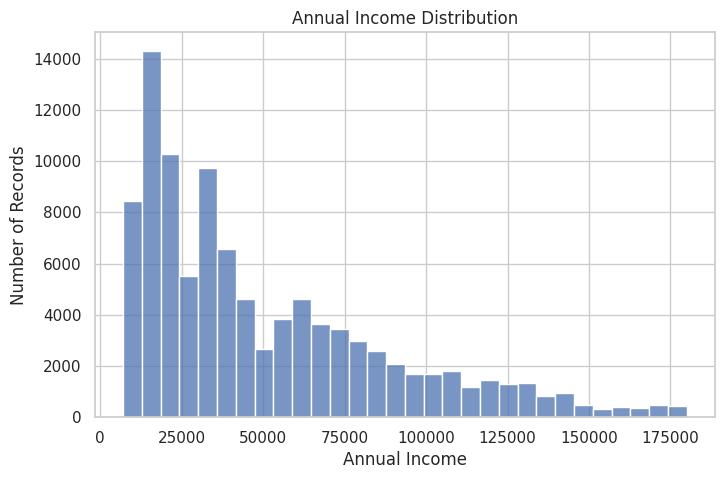

In [135]:
plt.figure(figsize=(8, 5))
sns.histplot(data=paisabazaar_df, x='Annual_Income', bins=30)
plt.title('Annual Income Distribution')
plt.xlabel('Annual Income')
plt.ylabel('Number of Records')
plt.show()

**Insight:** Income ranges from 7,006 to 179,987. The mean (50,505) is higher than the median (36,999.7), so most customers earn less than the average and a smaller group earns very high incomes.

**So what:** Most customers are in the low-to-middle income range, so products should be designed mainly for them.

### 4.2 Bivariate Analysis: Credit Score vs Other Features

#### Chart 4: Average Number of Loans by Credit Score

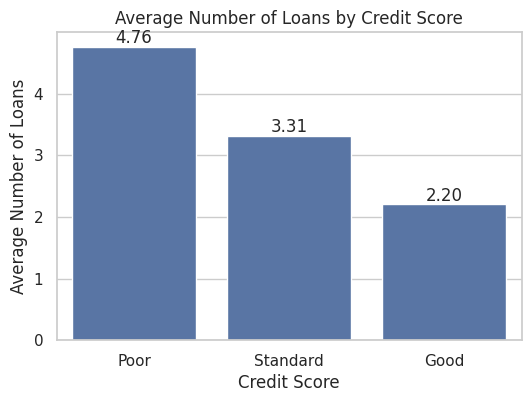

In [136]:
plt.figure(figsize=(6, 4))
ax = sns.barplot(data=paisabazaar_df, x='Credit_Score', y='Num_of_Loan',
                 order=['Poor', 'Standard', 'Good'], errorbar=None)
ax.bar_label(ax.containers[0], fmt='%.2f')
plt.title('Average Number of Loans by Credit Score')
plt.xlabel('Credit Score')
plt.ylabel('Average Number of Loans')
plt.show()

**Insight:** Poor-score customers have 4.76 loans on average, compared to 3.31 for Standard and 2.20 for Good.

**So what:** Customers with many loans need a closer repayment check before a new loan is approved.

#### Chart 5: Average Number of Credit Cards by Credit Score

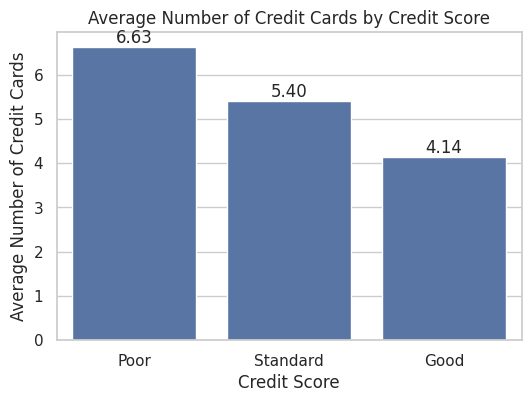

In [137]:
plt.figure(figsize=(6, 4))
ax = sns.barplot(data=paisabazaar_df, x='Credit_Score', y='Num_Credit_Card',
                 order=['Poor', 'Standard', 'Good'], errorbar=None)
ax.bar_label(ax.containers[0], fmt='%.2f')
plt.title('Average Number of Credit Cards by Credit Score')
plt.xlabel('Credit Score')
plt.ylabel('Average Number of Credit Cards')
plt.show()

**Insight:** Poor-score customers hold 6.63 credit cards on average, compared to 5.40 for Standard and 4.14 for Good.

**So what:** Holding many credit cards goes together with a lower score, so card count can serve as an early risk signal.

#### Chart 6: Number of Delayed Payments by Credit Score

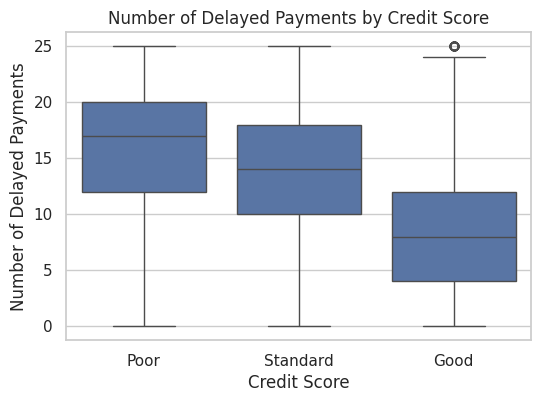

In [138]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=paisabazaar_df, x='Credit_Score', y='Num_of_Delayed_Payment',
            order=['Poor', 'Standard', 'Good'])
plt.title('Number of Delayed Payments by Credit Score')
plt.xlabel('Credit Score')
plt.ylabel('Number of Delayed Payments')
plt.show()

**Insight:** The median number of delayed payments is 17 for Poor customers, 14 for Standard and 8 for Good. The middle 50% of Good customers have 4 to 12 delays, while for Poor customers it is 12 to 20.

**So what:** Payment delays separate the groups clearly, so customers with frequent delays should be flagged early.

#### Chart 7: Median Debt-to-Income Ratio by Credit Score

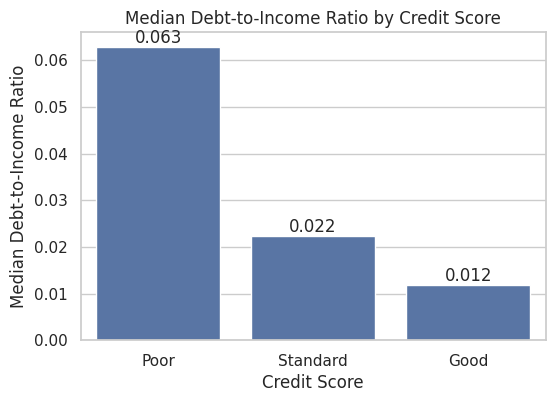

In [139]:
plt.figure(figsize=(6, 4))
ax = sns.barplot(data=paisabazaar_df, x='Credit_Score', y='Debt_to_Income',
                 order=['Poor', 'Standard', 'Good'], estimator='median', errorbar=None)
ax.bar_label(ax.containers[0], fmt='%.3f')
plt.title('Median Debt-to-Income Ratio by Credit Score')
plt.xlabel('Credit Score')
plt.ylabel('Median Debt-to-Income Ratio')
plt.show()

**Insight:** The median debt-to-income ratio is 0.063 for Poor customers, 0.022 for Standard and 0.012 for Good. Poor customers carry about 5 times more debt relative to their income than Good customers.

**So what:** Debt relative to income separates the score groups more clearly than income alone, so it is a stronger risk indicator than income by itself.

#### Chart 8: Annual Income by Credit Score

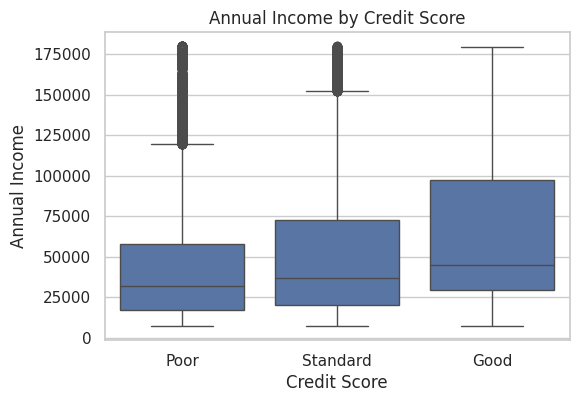

In [140]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=paisabazaar_df, x='Credit_Score', y='Annual_Income',
            order=['Poor', 'Standard', 'Good'])
plt.title('Annual Income by Credit Score')
plt.xlabel('Credit Score')
plt.ylabel('Annual Income')
plt.show()

**Insight:** Median annual income is 32,065 for Poor, 36,824 for Standard and 44,928 for Good customers. However, the ranges overlap heavily: the middle 50% of Poor customers earn 16,771 to 57,878, and for Good customers it is 29,710 to 97,417.

**So what:** Higher income goes with a better score on average, but many Poor customers earn as much as Good customers. Income alone does not explain credit score, and behaviour such as loans, delays and debt matters more.

#### Chart 9: Average Credit Utilization by Credit Score

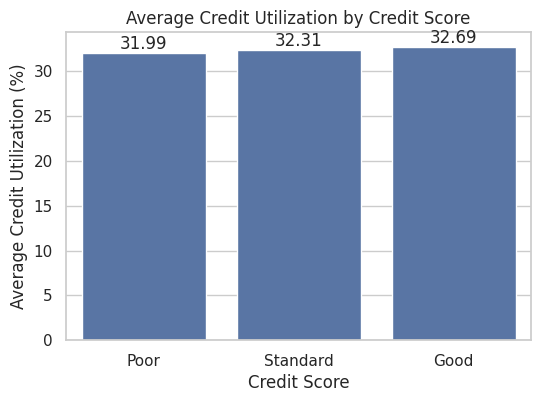

In [141]:
plt.figure(figsize=(6, 4))
ax = sns.barplot(data=paisabazaar_df, x='Credit_Score', y='Credit_Utilization_Ratio',
                 order=['Poor', 'Standard', 'Good'], errorbar=None)
ax.bar_label(ax.containers[0], fmt='%.2f')
plt.title('Average Credit Utilization by Credit Score')
plt.xlabel('Credit Score')
plt.ylabel('Average Credit Utilization (%)')
plt.show()

**Insight:** Average credit utilization is almost the same in all three groups: 31.99% for Poor, 32.31% for Standard and 32.69% for Good. Good customers are even slightly higher.

**So what:** Utilization does not separate good and poor customers in this dataset, which goes against the common assumption that high utilization means high risk. It should not be used on its own to judge risk.

#### Chart 10: Credit Score by Credit Mix

Credit_Score  Poor  Standard  Good
Credit_Mix                        
Bad           60.1      38.4   1.5
Standard      21.5      72.8   5.7
Good          16.0      35.2  48.9


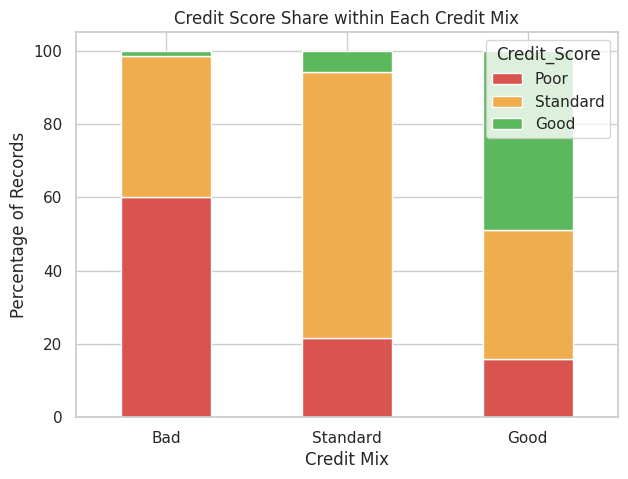

In [142]:
# Percentage of Poor, Standard, Good inside each Credit Mix group
mix = pd.crosstab(paisabazaar_df['Credit_Mix'], paisabazaar_df['Credit_Score'], normalize='index') * 100
mix = mix.loc[['Bad', 'Standard', 'Good'], ['Poor', 'Standard', 'Good']]

print(mix.round(1))
mix.plot(kind='bar', stacked=True, figsize=(7, 5), color=['#d9534f', '#f0ad4e', '#5cb85c'])
plt.title('Credit Score Share within Each Credit Mix')
plt.xlabel('Credit Mix')
plt.ylabel('Percentage of Records')
plt.xticks(rotation=0)
plt.show()

**Insight:** Among customers with a Bad credit mix, 60.1% have a Poor score, compared to 21.5% for a Standard mix and 16.0% for a Good mix. At the other end, 48.9% of customers with a Good mix have a Good score, but only 1.5% of those with a Bad mix do.

**So what:** Credit mix is a strong indicator of credit score. A Bad mix customer is about 3.8 times more likely to have a Poor score than a Good mix customer, so customers with a Bad mix should be reviewed more carefully.

#### Chart 11: Credit Score by Minimum-Amount Payment

Credit_Score           Poor  Standard  Good
Payment_of_Min_Amount                      
Yes                    39.6      56.8   3.7
No                     13.4      48.3  38.3
Unknown                29.3      52.0  18.7


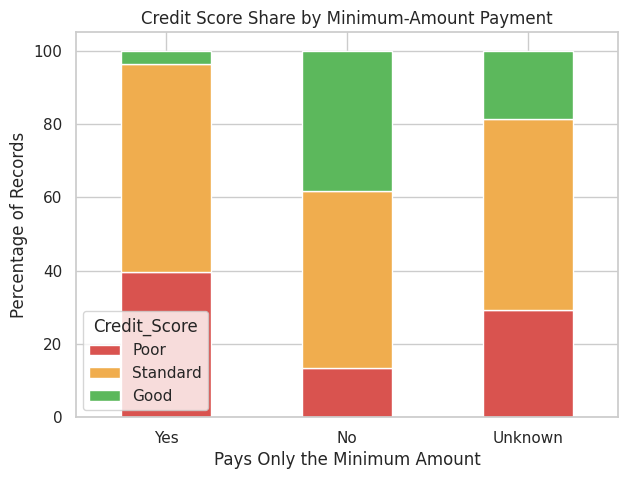

In [143]:
# Percentage of Poor, Standard, Good inside each payment group
pay = pd.crosstab(paisabazaar_df['Payment_of_Min_Amount'], paisabazaar_df['Credit_Score'], normalize='index') * 100
pay = pay.loc[['Yes', 'No', 'Unknown'], ['Poor', 'Standard', 'Good']]

print(pay.round(1))
pay.plot(kind='bar', stacked=True, figsize=(7, 5), color=['#d9534f', '#f0ad4e', '#5cb85c'])
plt.title('Credit Score Share by Minimum-Amount Payment')
plt.xlabel('Pays Only the Minimum Amount')
plt.ylabel('Percentage of Records')
plt.xticks(rotation=0)
plt.show()

**Insight:** Among customers who pay only the minimum amount (`Yes`), 39.6% have a Poor score, compared to 13.4% among those who do not (`No`). The reverse holds for Good scores: 38.3% of `No` customers have a Good score, but only 3.7% of `Yes` customers do. The `Unknown` group sits in between, with 29.3% Poor and 18.7% Good.

**So what:** Paying only the minimum amount is a strong warning sign: these customers are about 3 times more likely to have a Poor score. Customers who regularly pay only the minimum should be flagged for early support or review.



#### Chart 12: Share of Poor-Score Customers by Number of Loans

Num_of_Loan
0    11.7
1    11.1
2    23.9
3    21.8
4    21.2
5    51.7
6    50.7
7    52.4
8    55.0
9    53.6
Name: Is_Poor, dtype: float64


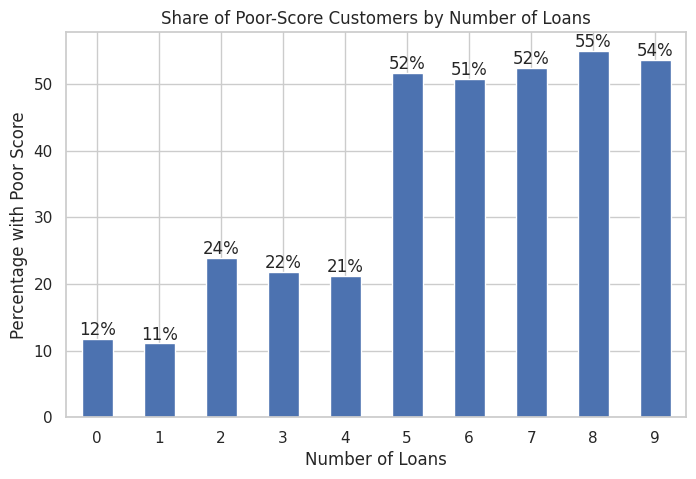

In [144]:
# Mark each record as Poor (True) or not (False)
paisabazaar_df['Is_Poor'] = paisabazaar_df['Credit_Score'] == 'Poor'

# Percentage of Poor customers for each loan count
poor_pct = paisabazaar_df.groupby(paisabazaar_df['Num_of_Loan'].astype(int))['Is_Poor'].mean() * 100

print(poor_pct.round(1))
plt.figure(figsize=(8, 5))
ax = poor_pct.plot(kind='bar')
ax.bar_label(ax.containers[0], fmt='%.0f%%')
plt.title('Share of Poor-Score Customers by Number of Loans')
plt.xlabel('Number of Loans')
plt.ylabel('Percentage with Poor Score')
plt.xticks(rotation=0)
plt.show()

In [145]:
loan_counts = paisabazaar_df['Num_of_Loan'].astype(int).value_counts().sort_index()
print(loan_counts)
print(f"\nRecords with 5 or more loans: {(paisabazaar_df['Num_of_Loan'] >= 5).mean():.1%}")

Num_of_Loan
0    11408
1    11128
2    15712
3    15752
4    15456
5     7528
6     8144
7     7680
8     3336
9     3856
Name: count, dtype: int64

Records with 5 or more loans: 30.5%


In [146]:
high_loan = paisabazaar_df['Num_of_Loan'] >= 5
poor_in_high = paisabazaar_df.loc[high_loan, 'Is_Poor'].sum()
print(f"Share of all Poor records that have 5+ loans: {poor_in_high / paisabazaar_df['Is_Poor'].sum():.1%}")

Share of all Poor records that have 5+ loans: 55.0%


**Insight:** The share of Poor-score customers stays low for customers with 0 or 1 loans (about 11%) and rises to 21% to 24% for 2 to 4 loans. At 5 loans it jumps to 51.7%, and it stays above 50% for every group from 5 to 9 loans (up to 55.0%). Customers with 5 or more loans make up 30.5% of all records but account for 55.0% of all Poor-score records.

**So what:** Customers with 5 or more loans form the high-risk segment: more than half of them have a Poor score, about 4 to 5 times the rate of customers with 0 or 1 loans. These customers should be reviewed more carefully before new credit is approved. This answers Question 3.

### 4.3 Multivariate Analysis

#### Chart 13: Correlation between Credit Score and Key Features

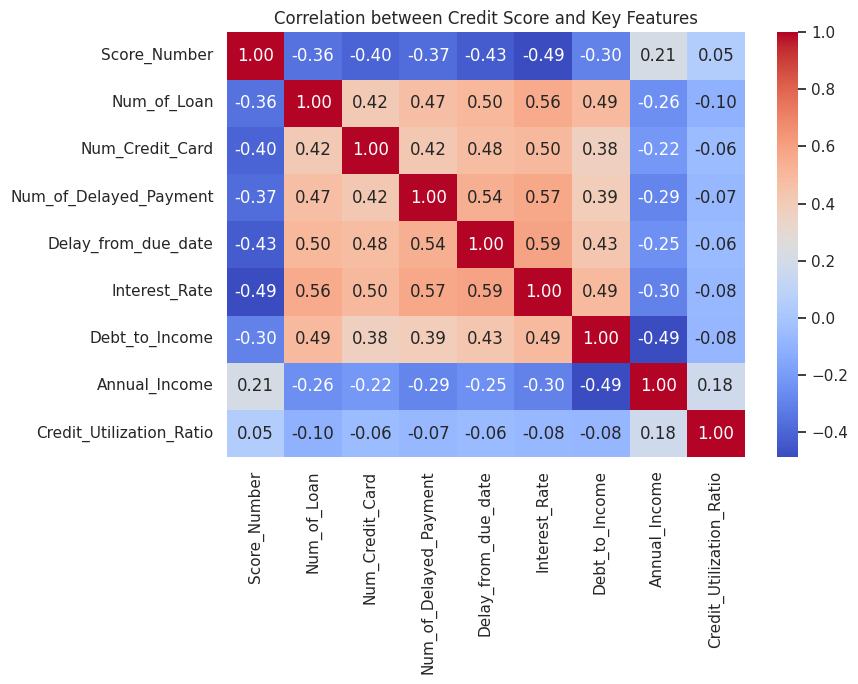

In [147]:
# Convert Credit_Score to numbers so it can be included: Poor=0, Standard=1, Good=2
paisabazaar_df['Score_Number'] = paisabazaar_df['Credit_Score'].map({'Poor': 0, 'Standard': 1, 'Good': 2})

cols = ['Score_Number', 'Num_of_Loan', 'Num_Credit_Card', 'Num_of_Delayed_Payment',
        'Delay_from_due_date', 'Interest_Rate', 'Debt_to_Income',
        'Annual_Income', 'Credit_Utilization_Ratio']

plt.figure(figsize=(9, 7))
sns.heatmap(paisabazaar_df[cols].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation between Credit Score and Key Features')
plt.tight_layout()
plt.show()

**Insight:** The features most strongly linked to credit score are interest rate (correlation -0.49), delay from due date (-0.43) and number of credit cards (-0.40), followed by delayed payments (-0.37) and number of loans (-0.36). Annual income has a weaker link (0.21), and credit utilization is close to zero (0.05).

**So what:** The negative sign means that as these values go up, the score goes down. The behaviour features are also correlated with each other (0.4 to 0.6), so they overlap and no single feature explains the score alone. Utilization again shows no real link, which matches Chart 9. Correlation shows a link, not a cause.

## 5. Statistical Check

The charts show that Poor-score customers have more delayed payments. A Kruskal-Wallis test checks whether the difference between the three score groups is real or could be due to chance. This test is used because it does not assume the data is normally distributed.

In [148]:
from scipy.stats import kruskal

poor = paisabazaar_df[paisabazaar_df['Credit_Score'] == 'Poor']['Num_of_Delayed_Payment']
standard = paisabazaar_df[paisabazaar_df['Credit_Score'] == 'Standard']['Num_of_Delayed_Payment']
good = paisabazaar_df[paisabazaar_df['Credit_Score'] == 'Good']['Num_of_Delayed_Payment']

stat, p_value = kruskal(poor, standard, good)
print("p-value: less than 0.001" if p_value < 0.001 else f"p-value: {p_value:.4f}")

p-value: less than 0.001


**Result:** The p-value is below 0.001, so the difference in delayed payments between Poor, Standard and Good customers is statistically significant.

**Note:** With 100,000 records, even small differences become statistically significant, and each customer appears 8 times, which makes the p-value look stronger than it really is. For this reason, the size of the difference (medians of 17, 14 and 8 delays) matters more than the p-value alone.

## 6. Summary Table

The table below collects the main findings from the charts in one place.

In [149]:
summary = paisabazaar_df.groupby('Credit_Score').agg(
    Avg_Loans=('Num_of_Loan', 'mean'),
    Avg_Credit_Cards=('Num_Credit_Card', 'mean'),
    Avg_Delayed_Payments=('Num_of_Delayed_Payment', 'mean'),
    Avg_Utilization=('Credit_Utilization_Ratio', 'mean'),
    Median_Debt_to_Income=('Debt_to_Income', 'median'),
    Median_Annual_Income=('Annual_Income', 'median')
).loc[['Poor', 'Standard', 'Good']].round(2)

summary

,Avg_Loans,Avg_Credit_Cards,Avg_Delayed_Payments,Avg_Utilization,Median_Debt_to_Income,Median_Annual_Income
Credit_Score,,,,,,
Poor,4.76,6.63,15.81,31.99,0.06,32064.86
Standard,3.31,5.40,13.54,32.31,0.02,36824.18
Good,2.20,4.14,8.56,32.69,0.01,44927.86


Poor-score customers have more loans, more credit cards, more delayed payments and a higher debt-to-income ratio than Good-score customers, and they earn less. Credit utilization is almost the same in all three groups, so it does not help separate them.

## 7. Conclusion

### Answers to the Business Questions

**1. Which behaviours separate Poor, Standard and Good credit scores?**
Poor-score customers have more loans (4.76 on average vs 2.20 for Good), more credit cards (6.63 vs 4.14), more delayed payments (15.81 vs 8.56) and a higher debt-to-income ratio (median 0.063 vs 0.012). They are also far more likely to pay only the minimum amount (39.6% of these customers have a Poor score vs 13.4% of those who do not) and to have a Bad credit mix (60.1% Poor vs 16.0% for a Good mix). Interest rate has the strongest link with the score (correlation -0.49).

**2. Does income alone explain credit score?**
No. Median income rises from 32,065 (Poor) to 44,928 (Good), but the ranges overlap heavily, and the correlation with score is only 0.21, weaker than loans, delays and interest rate.

**3. Which customer segment carries the highest risk?**
Customers with 5 or more loans. They make up 30.5% of all records but 55.0% of all Poor-score records, and more than half of them have a Poor score.

**Credit utilization does not help.** It is almost identical across the three groups (about 32%), so high utilization should not be treated as a risk signal on its own in this dataset.

### Recommendations

1. **Review customers with 5 or more loans more closely** before approving new credit, since more than half of them have a Poor score.
2. **Flag frequent delayed payments early.** Poor customers average about 16 delays against about 9 for Good customers.
3. **Watch customers who pay only the minimum amount**, who are about 3 times more likely to have a Poor score.
4. **Use debt-to-income together with income.** Income alone separates the groups weakly, while the debt-to-income ratio separates them clearly.
5. **Do not rely on credit utilization alone** when judging risk.

### Limitations

- The data contains 8 monthly records for each of 12,500 customers, so records are not independent, and the percentages describe records, not unique customers.
- The analysis shows links between features and credit score, not causes. For example, interest rate and credit mix may partly be results of a customer's score rather than reasons for it.
- Significance tests on 100,000 rows are very sensitive, so the size of the differences matters more than the p-values.
- No prediction model was built, so the strength of each feature in predicting the score has not been measured.
- The dataset is a snapshot, and it is unknown how representative it is of all Paisabazaar customers.